# Lab assignment №1, part 2

This lab assignment consists of several parts. You are supposed to make some transformations, train some models, estimate the quality of the models and explain your results.

Several comments:
* Don't hesitate to ask questions, it's a good practice.
* No private/public sharing, please. The copied assignments will be graded with 0 points.
* Blocks of this lab will be graded separately.

__*This is the second part of the assignment. First and third parts are waiting for you in the same directory.*__

## Part 2. Data preprocessing, model training and evaluation.

### 1. Reading the data
Today we work with the [dataset](https://archive.ics.uci.edu/ml/datasets/Statlog+%28Vehicle+Silhouettes%29), describing different cars for multiclass ($k=4$) classification problem. The data is available below.

In [ ]:
# If on colab, uncomment the following lines

# ! wget https://raw.githubusercontent.com/girafe-ai/ml-course/22f_made/homeworks/lab01_ml_pipeline/car_data.csv

--2026-11-05 17:59:02--  https://raw.githubusercontent.com/girafe-ai/ml-course/22f_made/homeworks/lab01_ml_pipeline/car_data.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 58374 (57K) [text/plain]
Saving to: ‘car_data.csv.1’

car_data.csv.1      100%[===================>]  57.01K  --.-KB/s    in 0.04s   

2026-11-05 17:59:02 (1.37 MB/s) - ‘car_data.csv.1’ saved [58374/58374]



In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

dataset = pd.read_csv('car_data.csv', delimiter=',', header=None).values
data = dataset[:, :-1].astype(int)
target = dataset[:, -1]
print(data.shape, target.shape)

X_train, X_test, y_train, y_test = train_test_split(data, target, test_size=0.35)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(846, 19) (846,)
(549, 19) (549,) (297, 19) (297,)


To get some insights about the dataset, `pandas` might be used. The `train` part is transformed to `pd.DataFrame` below.

In [ ]:
X_train_pd = pd.DataFrame(X_train)

# First 15 rows of our dataset.
X_train_pd.head(15)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
0,285,89,48,85,189,64,8,169,39,20,153,188,427,190,64,16,5,195,201
1,189,90,36,78,179,64,8,157,42,19,126,182,367,142,66,1,20,192,198
2,821,104,56,96,231,74,11,220,30,25,172,223,713,218,73,6,16,186,195
3,686,88,40,69,146,59,7,130,51,18,134,147,252,144,64,1,1,193,200
4,818,95,43,96,202,65,10,189,35,22,143,217,534,166,71,6,27,190,197
5,120,89,37,54,119,53,5,134,50,18,127,151,266,146,79,16,14,184,185
6,230,85,35,47,110,55,3,117,57,17,122,136,203,139,89,5,9,180,184
7,115,95,47,88,162,64,11,159,43,20,157,176,371,185,71,12,13,189,198
8,449,91,39,82,164,68,10,143,46,19,137,164,308,158,68,13,9,191,201
9,322,87,43,65,127,56,8,149,46,19,143,169,322,171,85,6,3,180,182


Methods `describe` and `info` deliver some useful information.

In [ ]:
X_train_pd.describe()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
count,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000
mean,425.539162,93.759563,44.790528,82.032787,169.628415,61.872495,8.550091,168.715847,40.896175,20.571949,147.828780,188.599271,439.051002,174.009107,72.364299,6.408015,12.890710,189.185792,195.934426
std,243.524315,8.286417,6.076596,15.808815,33.619115,7.723445,4.604400,32.635000,7.706415,2.537460,14.353457,31.135559,172.890237,31.836975,7.737851,4.970461,9.103565,6.290859,7.565003
min,0.000000,73.000000,33.000000,40.000000,104.000000,47.000000,2.000000,112.000000,26.000000,17.000000,118.000000,130.000000,184.000000,109.000000,59.000000,0.000000,0.000000,176.000000,181.000000
25%,208.000000,88.000000,40.000000,70.000000,141.000000,57.000000,7.000000,147.000000,33.000000,19.000000,137.000000,168.000000,319.000000,149.000000,67.000000,2.000000,6.000000,184.000000,191.000000
50%,432.000000,93.000000,44.000000,79.000000,169.000000,62.000000,8.000000,157.000000,43.000000,20.000000,146.000000,178.000000,364.000000,174.000000,71.000000,6.000000,11.000000,189.000000,197.000000
75%,638.000000,100.000000,49.000000,98.000000,197.000000,65.000000,10.000000,198.000000,46.000000,23.000000,159.000000,216.000000,586.000000,195.000000,75.000000,9.000000,19.000000,194.000000,201.000000
max,845.000000,117.000000,59.000000,112.000000,333.000000,138.000000,55.000000,262.000000,61.000000,28.000000,188.000000,320.000000,987.000000,268.000000,135.000000,22.000000,41.000000,206.000000,211.000000


In [ ]:
X_train_pd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 549 entries, 0 to 548
Data columns (total 19 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   0       549 non-null    int64
 1   1       549 non-null    int64
 2   2       549 non-null    int64
 3   3       549 non-null    int64
 4   4       549 non-null    int64
 5   5       549 non-null    int64
 6   6       549 non-null    int64
 7   7       549 non-null    int64
 8   8       549 non-null    int64
 9   9       549 non-null    int64
 10  10      549 non-null    int64
 11  11      549 non-null    int64
 12  12      549 non-null    int64
 13  13      549 non-null    int64
 14  14      549 non-null    int64
 15  15      549 non-null    int64
 16  16      549 non-null    int64
 17  17      549 non-null    int64
 18  18      549 non-null    int64
dtypes: int64(19)
memory usage: 81.6 KB


### 2. Machine Learning pipeline
Here you are supposed to perform the desired transformations. Please, explain your results briefly after each task.

#### 2.0. Data preprocessing
* Make some transformations of the dataset (if necessary). Briefly explain the transformations

In [ ]:
### YOUR CODE
print(X_train_pd.memory_usage().sum())
X_train_pd.max().max(), X_train_pd.min().min()

83580


(987, 0)

In [ ]:
X_train_pd = X_train_pd.astype('int16')
print(X_train_pd.memory_usage().sum())
X_train_pd.max().max(), X_train_pd.min().min()

20994


(np.int16(987), np.int16(0))

In [ ]:
print(X_train_pd.shape, y_train.shape)
print(X_train_pd.isna().sum().sum())

(549, 19) (549,)
0


#### 2.1. Basic logistic regression
* Find optimal hyperparameters for logistic regression with cross-validation on the `train` data (small grid/random search is enough, no need to find the *best* parameters).

* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression: `multi_class='multinomial'`, `solver='saga'` `tol=1e-3` and ` max_iter=500`.*

In [ ]:
from numpy.random import multinomial
### YOUR CODE HERE
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import f1_score, accuracy_score, roc_curve, classification_report


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        multi_class='multinomial',
        solver='saga',
        tol=1e-3,
        max_iter=500,
        random_state=1
    ))
])

parameters_grid = {
    'model__C': [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

grid = GridSearchCV(
    pipe,
    param_grid=parameters_grid,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1
)

grid.fit(X_train, y_train)
be = grid.best_estimator_
y_pred = be.predict(X_test)
y_prob = be.predict_proba(X_test)

print('Лучшие параметры: ', grid.best_params_)
print('CV f1-macro: ', grid.best_score_)
print('Accuracy: ', accuracy_score(y_test, y_pred))
print('f1-macro: ', f1_score(y_test, y_pred, average='macro'))
print(classification_report(y_test, y_pred))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Лучшие параметры:  {'model__C': 1000}
CV f1-macro:  0.7827155470983198
Accuracy:  0.7845117845117845
f1-macro:  0.7885541204214535
              precision    recall  f1-score   support

         bus       0.93      0.93      0.93        71
        opel       0.70      0.58      0.63        85
        saab       0.60      0.69      0.64        70
         van       0.92      0.99      0.95        71

    accuracy                           0.78       297
   macro avg       0.79      0.79      0.79       297
weighted avg       0.78      0.78      0.78       297



In [ ]:
# You might use this command to install scikit-plot.
# Warning, if you a running locally, don't call pip from within jupyter, call it from terminal in the corresponding
# virtual environment instead

# ! pip install scikit-plot

#### 2.2. PCA: explained variance plot
* Apply the PCA to the train part of the data. Build the explaided variance plot.

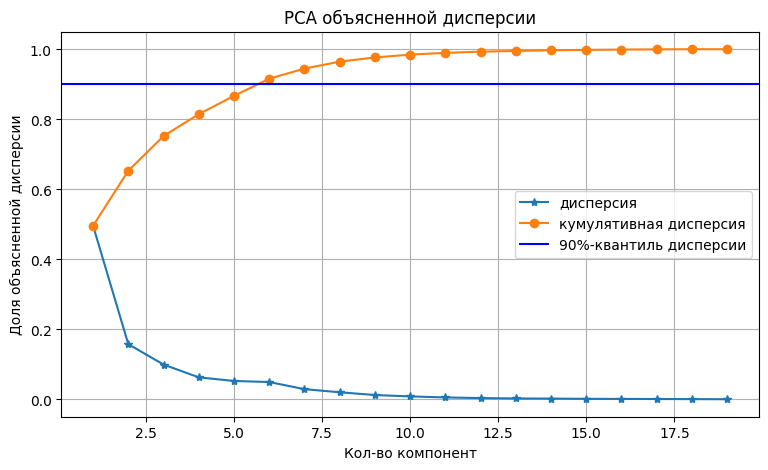

In [ ]:
### YOUR CODE
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
pca = PCA()
pca.fit(X_train_sc)
explained = pca.explained_variance_ratio_
cum = np.cumsum(explained)

plt.figure(figsize=(9, 5))
plt.plot(range(1, len(explained) + 1), explained, marker='*', label='дисперсия')
plt.plot(range(1, len(cum) + 1), cum, marker='o', label='кумулятивная дисперсия')
plt.axhline(0.9, color='blue', linestyle='-', label='90%-квантиль дисперсии')
plt.xlabel('Кол-во компонент')
plt.ylabel('Доля объясненной дисперсии')
plt.title('PCA объясненной дисперсии')
plt.legend()
plt.grid()
plt.show()

#### 2.3. PCA trasformation
* Select the appropriate number of components. Briefly explain your choice. Should you normalize the data?

*Use `fit` and `transform` methods to transform the `train` and `test` parts.*

In [ ]:
### YOUR CODE
n_components = np.argmax(cum >= 0.9) + 1
print("Кол-во комопонент: ", n_components)
print("Объясненная дисперсия:", cum[n_components - 1])
pca = PCA(n_components=n_components)

X_train_pca = pca.fit_transform(X_train_sc)
X_test_sc = scaler.transform(X_test)
X_test_pca = pca.transform(X_test_sc)

print(X_train_sc.shape, X_test_pca.shape)

Кол-во комопонент:  6
Объясненная дисперсия: 0.9157651095166857
(549, 19) (297, 6)


Выбрано 6 главных компонент, т.к. они объясняют примерно 91.58% общей дисперсии исходных данных. Это позволяет сократить количество признаков с 19 до 6, сохранив достаточно информации.

Перед применением PCA данные нужно стандартизировать, т.к. признаки могут иметь разные масштабы. Без стандартизации признаки с большими значениями могут оказывать непропорционально сильное влияние на главные компоненты.

Стандартизация и PCA обучались только на тренировочной выборке, после чего применялись к тренировочной и тестовой выборкам. Это позволяет избежать утечки данных.

**Note: From this point `sklearn` [Pipeline](https://scikit-learn.org/stable/modules/compose.html) might be useful to perform transformations on the data. Refer to the [docs](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) for more information.**

#### 2.4. Logistic regression on PCA-preprocessed data.
* Find optimal hyperparameters for logistic regression with cross-validation on the transformed by PCA `train` data.

* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression: `multi_class='multinomial'`, `solver='saga'` and `tol=1e-3`*

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Лучшие параметры:  {'C': 10}
CV f1-macro:  0.4128365948129554
Accuracy:  0.44107744107744107
f1-macro:  0.4285491376936813


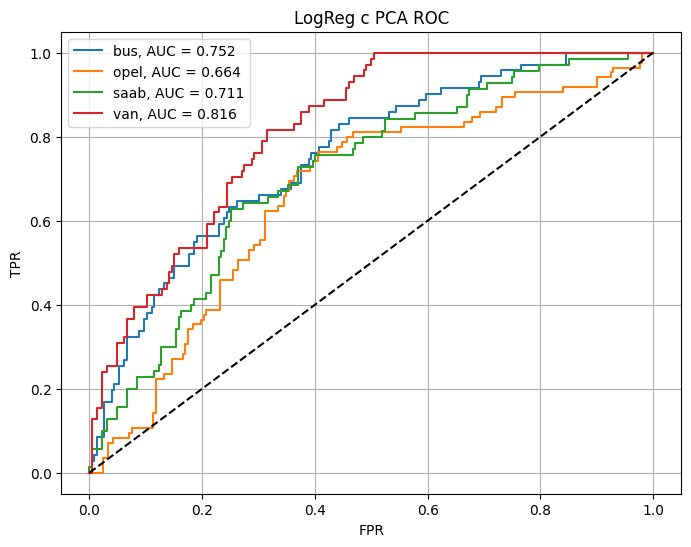

In [ ]:
### YOUR CODE HERE
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc

def plot_multiclass_roc(y_true, probs, classes, title):
    y_bin = label_binarize(y_true, classes=classes)
    plt.figure(figsize=(8, 6))

    for i, cls in enumerate(classes):
        fpr, tpr, _ = roc_curve(y_bin[:, i], probs[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f'{cls}, AUC = {roc_auc:.3f}')

    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('FPR')
    plt.ylabel('TPR')
    plt.title(title)
    plt.legend()
    plt.grid()
    plt.show()

classes = np.unique(y_train)

grid_pca = GridSearchCV(
    LogisticRegression(
        multi_class='multinomial',
        solver='saga',
        tol=1e-3,
        max_iter=500,
        random_state=1
    ),
    {'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000]},
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1
)

grid_pca.fit(X_train_pca, y_train)
pca = grid_pca.best_estimator_
y_pred_pca = pca.predict(X_test_pca)
prob_pca = pca.predict_proba(X_test_pca)

print('Лучшие параметры: ', grid_pca.best_params_)
print('CV f1-macro: ', grid_pca.best_score_)
print('Accuracy: ', accuracy_score(y_test, y_pred_pca))
print('f1-macro: ', f1_score(y_test, y_pred_pca, average='macro'))
plot_multiclass_roc(y_test, prob_pca, classes, 'LogReg с PCA ROC')

#### 2.5. Decision tree
* Now train a desicion tree on the same data. Find optimal tree depth (`max_depth`) using cross-validation.

* Measure the model quality using the same metrics you used above.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# YOUR CODE
grid_tree = GridSearchCV(
    DecisionTreeClassifier(random_state=1),
    {'max_depth': [2, 3, 4, 5, 6, 8, 10, 15, None]},
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1
)

grid_tree.fit(X_train, y_train)
tree = grid_tree.best_estimator_
y_pred_tree = tree.predict(X_test)

print('Лучшие параметры: ', grid_tree.best_params_)
print('CV f1-macro: ', grid_tree.best_score_)
print('Accuracy: ', accuracy_score(y_test, y_pred_tree))
print('f1-macro: ', f1_score(y_test, y_pred_tree, average='macro'))

Лучшие параметры:  {'max_depth': 15}
CV f1-macro:  0.6897300137147881
Accuracy:  0.6767676767676768
f1-macro:  0.677178194511044


#### 2.6. Bagging.
Here starts the ensembling part.

First we will use the __Bagging__ approach. Build an ensemble of $N$ algorithms varying N from $N_{min}=2$ to $N_{max}=100$ (with step 5).

We will build two ensembles: of logistic regressions and of decision trees.

*Comment: each ensemble should be constructed from models of the same family, so logistic regressions should not be mixed up with decision trees.*


*Hint 1: To build a __Bagging__ ensebmle varying the ensemble size efficiently you might generate $N_{max}$ subsets of `train` data (of the same size as the original dataset) using bootstrap procedure once. Then you train a new instance of logistic regression/decision tree with optimal hyperparameters you estimated before on each subset (so you train it from scratch). Finally, to get an ensemble of $N$ models you average the $N$ out of $N_{max}$ models predictions.*

*Hint 2: sklearn might help you with this taks. Some appropriate function/class might be out there.*

* Plot `f1` and `accuracy` scores plots w.r.t. the size of the ensemble.

* Briefly analyse the plot. What is the optimal number of algorithms? Explain your answer.

* How do you think, are the hyperparameters for the decision trees you found in 2.5 optimal for trees used in ensemble?

In [ ]:
# YOUR CODE
from sklearn.base import clone
from tqdm import tqdm

N_vals = [2] + list(range(5, 101, 5))
N_max = max(N_vals)
rng = np.random.default_rng(1)
n_train = len(y_train)
bootstrap_idx = [rng.integers(0, n_train, size=n_train)
                 for _ in range(N_max)]
models = []
tree_models = []

for idx in tqdm(bootstrap_idx):
    model = clone(be)
    model.fit(X_train[idx], y_train[idx])
    models.append(model)

    model_tree = clone(tree)
    model_tree.fit(X_train[idx], y_train[idx])
    tree_models.append(model_tree)

print('Кол-во регрессий:', len(models))
print('Кол-во решающих деревьев:', len(tree_models))

  0%|          | 0/100 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
  1%|          | 1/100 [00:00<00:10,  9.36it/s]/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
  2%|▏         | 2/100 [00:00<00:10,  9.28it/s]/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
  3%|▎      

Кол-во регрессий: 100
Кол-во решающих деревьев: 100


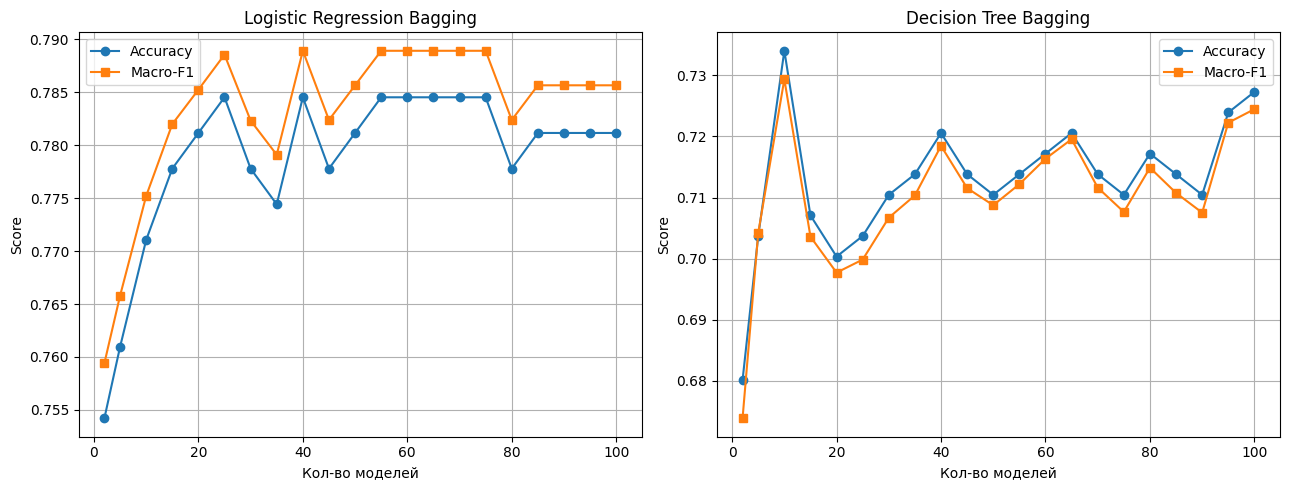

Best logistic bagging size:
N           40.000000
accuracy     0.784512
f1           0.788908
Name: 8, dtype: float64
Best tree bagging size:
N           10.000000
accuracy     0.734007
f1           0.729344
Name: 2, dtype: float64


In [ ]:
def evaluate_bagging(models, X_test, y_test, N_vals):
    results = []
    probs = [model.predict_proba(X_test) for model in models]

    for n in N_vals:
        mean_proba = np.mean(probs[:n], axis=0)
        y_pred = models[0].classes_[np.argmax(mean_proba, axis=1)]
        results.append({
            'N': n,
            'accuracy': accuracy_score(y_test, y_pred),
            'f1': f1_score(y_test, y_pred, average='macro')
        })

    return pd.DataFrame(results)

bagging = evaluate_bagging(models, X_test, y_test, N_vals)
bagging_tree = evaluate_bagging(tree_models, X_test, y_test, N_vals)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, results, name in [
    (axes[0], bagging, 'Logistic Regression Bagging'),
    (axes[1], bagging_tree, 'Decision Tree Bagging')
    ]:
    ax.plot(results['N'], results['accuracy'], marker='o', label='Accuracy')
    ax.plot(results['N'], results['f1'], marker='s', label='Macro-F1')
    ax.set_xlabel('Кол-во моделей')
    ax.set_ylabel('Score')
    ax.set_title(name)
    ax.legend()
    ax.grid()

plt.tight_layout()
plt.show()

print('Best logistic bagging size:')
print(bagging.loc[bagging['f1'].idxmax()])
print('Best tree bagging size:')
print(bagging_tree.loc[bagging_tree['f1'].idxmax()])

Результаты показывают, что Bagging улучшает качество обеих моделей, но эффект различается.

Для логистической регрессии лучший результат достигается при 40 моделях:
- Accuracy: 0.7845
- Macro-F1: 0.7889

С увеличением размера ансамбля качество сначала растёт, потом становится стабильным. После 40 практически нет заметного улучшения. Поэтому 40 моделей можно считать оптимальным размером ансамбля.

Для деревьев решений лучший результат достигается при использовании 10 моделей:
- Accuracy: 0.7340
- Macro-F1: 0.7293

Результаты сильнее колеблются в зависимости от размера ансамбля. Увеличение количества деревьев не приводит к стабильному улучшению качества. Поэтому среди проверенных вариантов 10 моделей дают наилучший Macro-F1.

В целом ансамбль логистических регрессий показывает лучшие результаты, чем ансамбль деревьев решений на данном наборе данных.

#### 2.7. Random Forest
Now we will work with the Random Forest (its `sklearn` implementation).

* * Plot `f1` and `accuracy` scores plots w.r.t. the number of trees in Random Forest.

* What is the optimal number of trees you've got? Is it different from the optimal number of logistic regressions/decision trees in 2.6? Explain the results briefly.

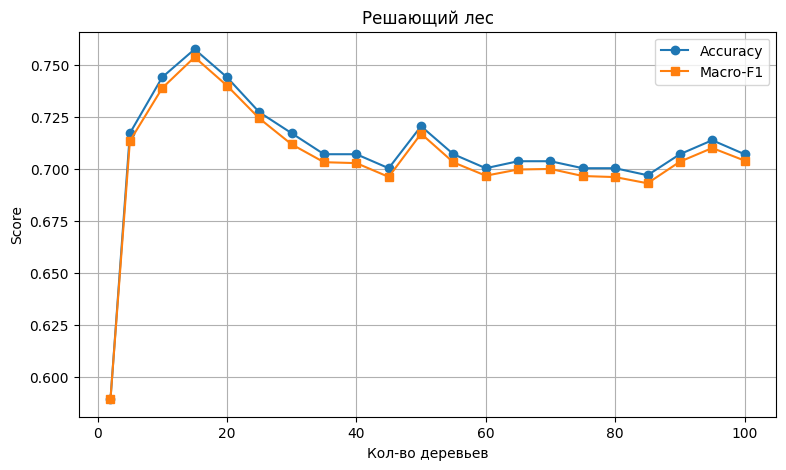

Best RF size by macro-F1:
N           15.000000
accuracy     0.757576
f1           0.753748
Name: 3, dtype: float64


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# YOUR CODE
N_rf = [2] + list(range(5, 101, 5))
rf = RandomForestClassifier(
    n_estimators=2,
    max_depth=grid_tree.best_params_['max_depth'],
    random_state=42,
    n_jobs=-1,
    warm_start=True
)
rf_results = []

for n in N_rf:
    rf.set_params(n_estimators=n)
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)
    rf_results.append({
        'N': n,
        'accuracy': accuracy_score(y_test, y_pred),
        'f1': f1_score(y_test, y_pred, average='macro')
    })

rf_results = pd.DataFrame(rf_results)
plt.figure(figsize=(9, 5))
plt.plot(rf_results['N'], rf_results['accuracy'], marker='o', label='Accuracy')
plt.plot(rf_results['N'], rf_results['f1'], marker='s', label='Macro-F1')
plt.xlabel('Кол-во деревьев')
plt.ylabel('Score')
plt.title('Решающий лес')
plt.legend()
plt.grid()
plt.show()

print('Best RF size by macro-F1:')
print(rf_results.loc[rf_results['f1'].idxmax()])

Лучший результат Random Forest достигается при использовании 15 деревьев:
- Accuracy: 0.7576
- Macro-F1: 0.7537

Оптимальное количество моделей:
- Bagging логистической регрессии: 40 моделей.
- Bagging деревьев решений: 10 моделей.
- Random Forest: 15 деревьев.

Это потому как Random Forest сочетает бутстреп-выборки со случайным выбором признаков при построении каждого разбиения. Это увеличивает разнообразие деревьев, поэтому относительно небольшого их количества может быть достаточно для получения хорошего результата.

Добавление новых деревьев не обязательно приводит к заметному улучшению качества на тестовой выборке. Значит среди проверенных вариантов 15 деревьев дают лучший результат.

#### 2.8. Learning curve
Your goal is to estimate, how does the model behaviour change with the increase of the `train` dataset size.

* Split the training data into 10 equal (almost) parts. Then train the models from above (Logistic regression, Desicion Tree, Random Forest) with optimal hyperparameters you have selected on 1 part, 2 parts (combined, so the train size in increased by 2 times), 3 parts and so on.

* Build a plot of `accuracy` and `f1` scores on `test` part, varying the `train` dataset size (so the axes will be score - dataset size.

* Analyse the final plot. Can you make any conlusions using it?

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and wi

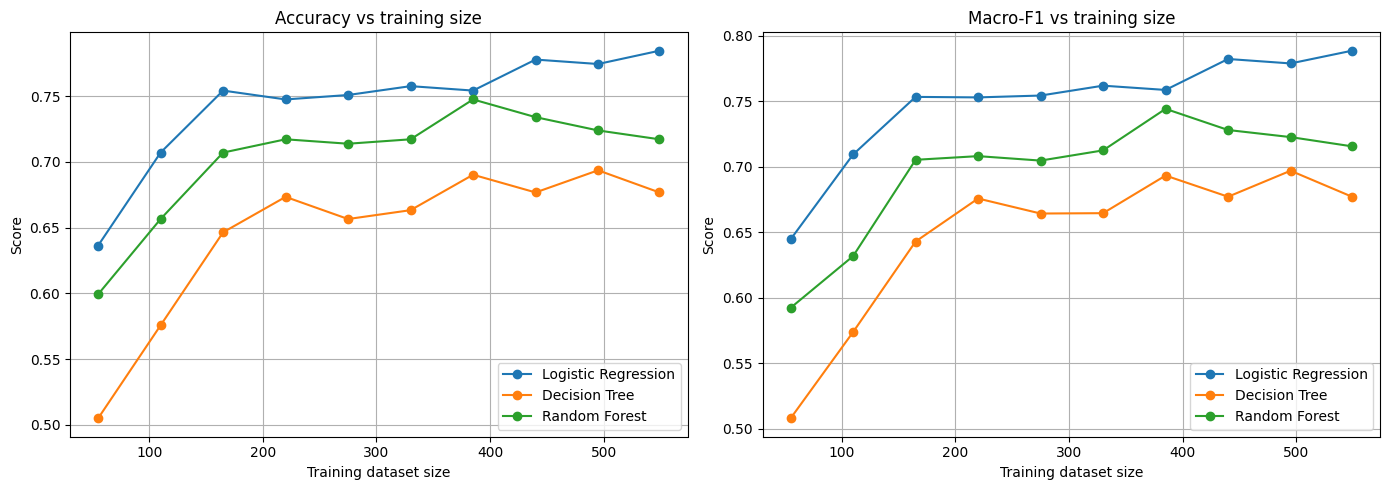

In [ ]:
# YOUR CODE HERE
from sklearn.base import clone

rng = np.random.default_rng(42)
order = rng.permutation(len(y_train))
X_shuffled = X_train[order]
y_shuffled = y_train[order]

models = {
    'Logistic Regression': be,
    'Decision Tree': tree,
    'Random Forest': RandomForestClassifier(
        n_estimators=int(rf_results.loc[rf_results['f1'].idxmax(), 'N']),
        max_depth=grid_tree.best_params_['max_depth'],
        random_state=42,
        n_jobs=-1
    )
}

learning_results = []

for part in range(1, 11):
    size = int(np.ceil(len(y_train) * part / 10))
    X_part = X_shuffled[:size]
    y_part = y_shuffled[:size]

    for name, model in models.items():
        fitted_model = clone(model)
        fitted_model.fit(X_part, y_part)
        pred = fitted_model.predict(X_test)
        learning_results.append({
            'size': size,
            'model': name,
            'accuracy': accuracy_score(y_test, pred),
            'f1': f1_score(y_test, pred, average='macro')
        })

learning_results = pd.DataFrame(learning_results)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name in models:
    subset = learning_results[learning_results['model'] == name]
    axes[0].plot(subset['size'], subset['accuracy'], marker='o', label=name)
    axes[1].plot(subset['size'], subset['f1'], marker='o', label=name)

axes[0].set_title('Accuracy vs training size')
axes[1].set_title('Macro-F1 vs training size')

for ax in axes:
    ax.set_xlabel('Training dataset size')
    ax.set_ylabel('Score')
    ax.legend()
    ax.grid()

plt.tight_layout()
plt.show()

Графики показывают, как изменяется качество трёх моделей при увеличении размера обучающей выборки.

**Логистическая регрессия** показывает наилучшие результаты. Значения Accuracy и Macro-F1 в целом растут с увеличением объёма обучающих данных. При добавлении новых наблюдений рост качества становится меньше, но макс. значения достигаются при использовании всей обучающей выборки.

**Дерево решений** показывает наихудшее качество среди трёх моделей. Метрики сильно колеблются при изменении размера выборки и не показывают значимый рост. Это может быть связано с высокой дисперсией отдельного дерева решений.

**Random Forest** работает лучше, чем одиночное дерево решений. Качество сильно улучшается при увеличении обучающей выборки с 55 до примерно 385 наблюдений. При дальнейшем увеличении выборки наблюдается небольшое снижение метрик. Это может быть связано со случайностью формирования выборок и обучения моделей.

+- логистическая регрессия лучше всего обобщает закономерности в данном наборе данных, а Random Forest превосходит одиночное дерево решений. Увеличение объёма обучающей выборки в большинстве случаев положительно влияет на качество моделей, хотя рост метрик не всегда монотонный (вроде видно около 6 участков монотонности). Также можно заметить, что по мере увеличения выборки прирост качества становится менее выраженным.

#### 2.9. Boosting
Your goal is to build a boosting ensemble using xgboost, CatBoost or lightgbm package.
Please, do not use the sklearn API for these models.

Find optimal number of decision trees in the boosting ensembe using grid search or other methods.
Please, explain your answer.

In [ ]:
# !pip install catboost

In [ ]:
# YOUR CODE HERE
from catboost import CatBoostClassifier
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

boost_model = CatBoostClassifier(
    iterations=1500,
    learning_rate=0.05,
    depth=6,
    loss_function='MultiClass',
    eval_metric='TotalF1',
    random_seed=42,
    verbose=100,
    early_stopping_rounds=100,
    allow_writing_files=False
)

boost_model.fit(
    X_fit,
    y_fit,
    eval_set=(X_val, y_val),
    verbose=100
)

print('Best iteration:', boost_model.get_best_iteration())
print('Best validation score:', boost_model.get_best_score())

0:	learn: 0.6255608	test: 0.5689151	best: 0.5689151 (0)	total: 62ms	remaining: 1m 32s
100:	learn: 0.9208139	test: 0.6994377	best: 0.7232800 (47)	total: 845ms	remaining: 11.7s
200:	learn: 0.9747546	test: 0.7517450	best: 0.7812533 (176)	total: 1.35s	remaining: 8.72s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.7812532922
bestIteration = 176

Shrink model to first 177 iterations.
Best iteration: 176
Best validation score: {'learn': {'TotalF1': 0.9908877797619344, 'MultiClass': 0.23677507373681406}, 'validation': {'TotalF1': 0.781253292162383, 'MultiClass': 0.5458163998256176}}


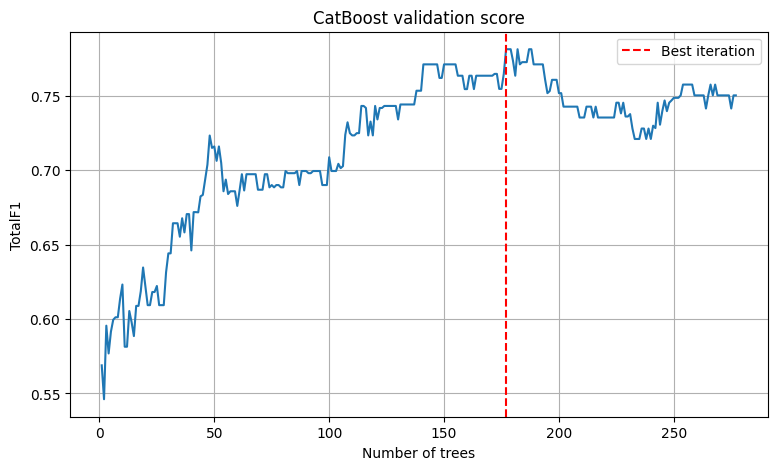

In [ ]:
eval_results = boost_model.get_evals_result()
val_metrics = eval_results['validation']
metric_name = 'TotalF1'

if metric_name not in val_metrics:
    metric_name = list(val_metrics.keys())[0]

scores = val_metrics[metric_name]
iterations = np.arange(1, len(scores) + 1)

plt.figure(figsize=(9, 5))
plt.plot(iterations, scores)
plt.axvline(
    boost_model.get_best_iteration() + 1,
    color='red',
    linestyle='--',
    label='Best iteration'
)
plt.xlabel('Number of trees')
plt.ylabel(metric_name)
plt.title('CatBoost validation score')
plt.legend()
plt.grid()
plt.show()

In [ ]:
best_iterations = max(1, boost_model.get_best_iteration() + 1)
final_boost = CatBoostClassifier(
    iterations=best_iterations,
    learning_rate=0.05,
    depth=6,
    loss_function='MultiClass',
    random_seed=42,
    verbose=False,
    allow_writing_files=False
)
final_boost.fit(X_train, y_train)
pred_boost = final_boost.predict(X_test).ravel()

print('Selected iterations:', best_iterations)
print('Test accuracy:', accuracy_score(y_test, pred_boost))
print('Test macro-F1:', f1_score(y_test, pred_boost, average='macro'))

Selected iterations: 177
Test accuracy: 0.7037037037037037
Test macro-F1: 0.6962367590850367


Для построения ансамбля использовался CatBoostClassifier. Оптимальное количество деревьев искалось с помощью early stopping на валидационной выборке.

В качестве начального значения было задано 1500 итераций, если метрика не улучшалась в течение 100 итераций обучение останавливалось.

Наилучшее значение Macro-F1 на валидационной выборке было достигнуто на 177-й итерации и составило 0.7813. Поэтому для финальной модели было выбрано 177 деревьев.

Результаты на тестовой выборке:
- Accuracy: 0.7037
- Macro-F1: 0.6962

CatBoost показал достаточно хорошее качество, но на тестовой выборке результат оказался ниже, чем у Bagging логистических регрессий (Macro-F1 = 0.7889) и Random Forest (Macro-F1 = 0.7537).

Качество на обучающей выборке сильно выше, чем на валидационной (TotalF1 = 0.9909 против 0.7813). Значит переобучение модели. Early stopping позволил ограничить количество деревьев и выбрать итерацию с наилучшим качеством на валидационной выборке.

Увеличение количества деревьев после 177-й итерации не давало устойчивого улучшения, поэтому дальнейшее обучение кажется нецелесообразно.